# Forecasting 3 — Final Assignment 

**Business context:** Sports retailer  
**Problem:** Predict weekly revenue for each store to help with staff and stock planning.  
**Dataset:** `group_03_forecasting_3.csv`  

We follow the six CRISP-DM phases. The numbers and graphs below come from our data and Python code.
**Revision status:** forecast-boundary timing corrected. Outputs have been cleared because this revision has not yet been executed in the submission environment. Restart the kernel, Run All and save before submission. The numerical interpretation cells generate their text from the current calculations.


## Phase 1 — Business Understanding

Store managers need a sales forecast before they order stock and plan staff. We assume that Sunday evening would be too late, because the case does not say when orders and staff schedules are decided. For this assignment, we choose Thursday before the target week as the planning day. This is our assumption, not a confirmed company deadline.

For example, on Thursday in week 10, we predict sales for week 11. Week 10 is not finished yet. The latest complete sales week is week 9. This means we must use sales from at least two weeks before the target week.

We predict weekly revenue (`sales_eur`) for each store. One row should represent one store-week, identified by `store_id` and `week_start`. We do not have product quantities in the dataset. Revenue forecasts can support general planning, but they cannot tell managers exactly how many products to order or staff members to schedule.

Our original success goal is at least 5% lower MAE than the two-week naive baseline (`lag_2`), without worse MAE for any store. We chose this as our own practical improvement target, not as a company rule. We keep this original goal even if later results show that another baseline is stronger. We do not know actual ordering deadlines or business costs, so the company must confirm these assumptions before use.


### Metric and operational interpretation

MAE is the average absolute revenue error in euros per store-week. It has the same unit as the forecast and is understandable for managers, but it treats equal-sized underforecasts and overforecasts equally. Bias adds direction; RMSE highlights large misses, and WAPE expresses error relative to aggregate recorded revenue. Equal store-week weighting in MAE makes the store breakdown important because store revenue levels differ.

Revenue MAE cannot be converted directly into misallocated staff hours, stock quantities or holding costs. That would require validated relationships between revenue, product mix, margins, labour productivity and planning decisions, plus cost data. Before operational use, managers should agree on acceptable error and asymmetric consequences; the 5% target remains our analytical improvement criterion, not a measured profitability threshold.


In [1]:
import sys
import hashlib
from importlib.metadata import version
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print('Python:', sys.version)
for package in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'scipy', 'ipykernel']:
    print(f'{package}=={version(package)}')
DATA = Path('group_03_forecasting_3.csv')
if not DATA.exists():
    raise FileNotFoundError('Place group_03_forecasting_3.csv beside this notebook and start Jupyter in that folder.')
print('CSV SHA-256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
raw = pd.read_csv(DATA)
print('Dataset shape:', raw.shape)
display(raw.head())


Python: 3.14.2 (main, Sep 10 2026, 12:33:04) [GCC 13.3.0]
numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
scikit-learn==1.8.0
scipy==1.18.1
ipykernel==7.3.0
CSV SHA-256: 245a746a37206f65143caba229a74e4166466dc02f08aadae0962856ca9ad471
Dataset shape: (1065, 11)


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
0,S06,25-11-2024,NONE,0,11.2,10.5,6875,27.82,36396.09,1279.27,medium
1,S02,22-07-2024,none,0,21.6,6.5,9128,19.57,46580.82,2236.76,high
2,S08,04-03-2024,Discount,0,2.9,0.6,7825,38.01,38589.62,1048.21,medium
3,S02,09-03-2026,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
4,S06,02-12-2024,none,1,1.2,0.4,8382,40.54,37143.15,1487.54,medium


## Phase 2 — Data Understanding

We first look at the data to understand what we are trying to predict. Each row should show the sales of one store in one week. Our target is `sales_eur`.

We check how many stores and weeks are in the data. We also look for missing values, repeated store-weeks and differences in weekly sales. This helps us decide what we need to prepare before making a forecast.

We also check which columns we can use on Thursday, before the week we want to predict. We should not use information that is only known after that week has finished.

### Variable meanings and availability

| Variable | Meaning and use |
|---|---|
| `store_id` | Store identifier; known before forecasting and encoded as store indicators. |
| `week_start` | Start of the revenue week; known calendar information and part of the key. |
| `sales_eur` | Recorded weekly revenue in euros; target. Only completed historical weeks may supply features or training labels. |
| `promo_label` | Recorded promotion category; excluded because advance availability is unconfirmed. |
| `holiday_week` | Holiday indicator; potentially known in advance, but excluded as a declared modelling choice. |
| `temperature_actual`, `rain_mm_actual` | Realised target-week weather; excluded because it is unavailable at prediction time. |
| `footfall_actual` | Realised visitors; excluded as a predictor. Historical training-period values support the data-quality diagnostic only. |
| `average_price_eur` | Recorded average price; calculation and advance availability are unconfirmed, so excluded. |
| `returns_next_week_eur` | Returns in the following week; future information, excluded. |
| `manager_sales_band_after_week` | Sales band assigned after the week; post-outcome information, excluded. |

These are interpretations of the supplied field names; the data owner must confirm definitions and publication delays. We assume a completed week's revenue is available before the following Thursday.


In [2]:
df = raw.copy()
df['week_start'] = pd.to_datetime(df['week_start'], dayfirst=True, errors='coerce')
print('Date range:', df.week_start.min(), 'to', df.week_start.max())
print('Stores:', df.store_id.nunique(), '| weeks:', df.week_start.nunique())
print('Missing by field:'); display(df.isna().sum().to_frame('missing'))
print('Duplicate store-week rows:', df.duplicated(['store_id','week_start']).sum())
print('Promo raw labels:'); display(df.promo_label.value_counts(dropna=False).to_frame('count'))
print('Sales distribution:'); display(df.sales_eur.describe().to_frame('sales_eur'))
print('Non-positive sales:', (df.sales_eur <= 0).sum())
print('Date parse failures:', df.week_start.isna().sum())
print('Five highest sales rows:')
display(df.nlargest(5,'sales_eur')[['store_id','week_start','sales_eur']])


Date range: 2024-01-01 00:00:00 to 2026-03-30 00:00:00
Stores: 9 | weeks: 118
Missing by field:


,missing
store_id,0
week_start,0
promo_label,71
holiday_week,0
temperature_actual,0
rain_mm_actual,0
footfall_actual,0
average_price_eur,18
sales_eur,0
returns_next_week_eur,0


Duplicate store-week rows: 3
Promo raw labels:


,count
promo_label,
none,470
discount,272
bundle,133
Discount,94
NaN,71
NONE,25


Sales distribution:


,sales_eur
count,1065.000000
mean,36832.336342
std,9816.546981
min,3791.040000
25%,32675.260000
50%,36118.020000
75%,42894.250000
max,169869.006000


Non-positive sales: 0
Date parse failures: 0
Five highest sales rows:


,store_id,week_start,sales_eur
808,S03,2024-10-21,169869.006
462,S09,2024-10-28,166970.214
628,S08,2025-02-24,142447.104
869,S01,2024-04-01,80249.730
459,S09,2025-11-03,51568.510


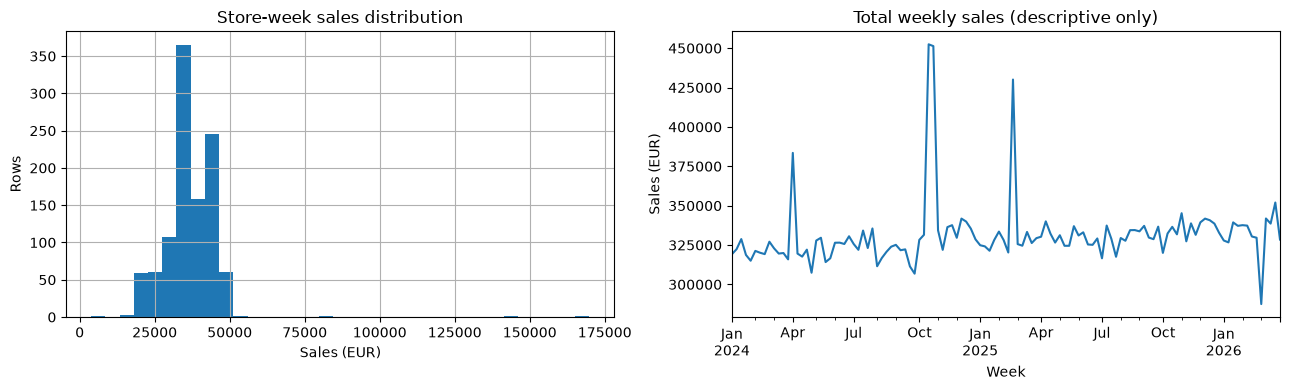

,count,mean,std,min,max
store_id,,,,,
S01,118,23082.44,5828.56,15809.59,80249.73
S02,119,45264.85,2155.83,39702.37,51059.85
S03,119,44741.58,11784.47,38473.75,169869.01
S04,118,35014.10,2198.38,28560.63,39736.14
S05,118,36673.81,2048.00,31185.51,41570.41
S06,118,34242.49,2185.74,29293.19,39723.21
S07,118,31319.16,2150.83,25027.86,36876.30
S08,118,36289.24,10058.92,30639.98,142447.10
S09,119,44658.54,12114.34,3791.04,166970.21


In [3]:
# Avoid counting repeated store-weeks twice in descriptive totals.
descriptive_panel = df.groupby(['store_id', 'week_start'], as_index=False).agg(sales_eur=('sales_eur', 'mean'))
fig, axes = plt.subplots(1,2,figsize=(13,4))
df.sales_eur.hist(ax=axes[0],bins=35)
axes[0].set(title='Store-week sales distribution',xlabel='Sales (EUR)',ylabel='Rows')
descriptive_panel.groupby('week_start').sales_eur.sum().sort_index().plot(ax=axes[1])
axes[1].set(title='Total weekly sales (descriptive only)',xlabel='Week',ylabel='Sales (EUR)')
plt.tight_layout(); plt.show()
display(df.groupby('store_id').sales_eur.agg(['count','mean','std','min','max']).round(2))

### What we found and what this means for Phase 1

**Dataset facts:** The dataset has 1,065 rows, 9 stores and 118 unique weeks. Three store-week keys appear twice. `promo_label` has 71 missing values and `average_price_eur` has 18 missing values. Store revenue levels are different, and the table above shows unusual high and low weeks. The sales-per-visitor check helps us spot values worth investigating, but does not prove an error.

**How this affects our business problem:** Phase 1 asks for one weekly revenue forecast per store. The duplicate keys challenge that requirement, so we must create one row per store-week. Different store sales levels mean we must also check errors for each store. Because we forecast on Thursday before the target week, actual footfall, weather and target-week sales cannot be used as predictors.

**Our assumptions and choices:** Thursday is our proposed planning moment, not a confirmed company deadline. We choose to keep unusual sales values unless they are verified as wrong. We use revenue because the dataset does not provide product quantities; the forecast cannot directly tell managers how many items to order.

**Example of an unusual value:** Store S09 has a recorded weekly revenue of **€3,791.04** in one week. This is a reason to investigate, not evidence that the value is wrong. The raw dataset contains **4** store-weeks with revenue above €60,000; these are descriptive counts, not automatic exclusions.

In [4]:
# Inspect unusually high and low revenue values. This is a data-quality check only.
inspect_cols = ['store_id','week_start','sales_eur','footfall_actual','promo_label','holiday_week']
unusual = pd.concat([df.nlargest(4,'sales_eur'),df.nsmallest(1,'sales_eur')])[inspect_cols].copy()
unusual['sales_per_visitor'] = (unusual.sales_eur / unusual.footfall_actual).round(2)
print('Unusual high and low store-weeks:')
display(unusual)
print('Median sales per visitor by store:')
display((df.sales_eur / df.footfall_actual).groupby(df.store_id).median().round(2))


Unusual high and low store-weeks:


,store_id,week_start,sales_eur,footfall_actual,promo_label,holiday_week,sales_per_visitor
808,S03,2024-10-21,169869.006,8721,none,0,19.48
462,S09,2024-10-28,166970.214,8509,discount,0,19.62
628,S08,2025-02-24,142447.104,7102,none,0,20.06
869,S01,2024-04-01,80249.730,4138,none,0,19.39
1013,S09,2026-03-02,3791.040,7623,discount,0,0.50


Median sales per visitor by store:


store_id
S01    5.36
S02    4.95
S03    5.07
S04    4.81
S05    5.00
S06    4.79
S07    4.81
S08    4.93
S09    5.00
dtype: float64

## Phase 3 — Data Preparation

We make **three substantive preparation decisions**. For each decision, we show the evidence, technique, before/after check, interpretation and next decision. The code directly below prints the checks.

**Decision 1 — Duplicate store-weeks**
- **Evidence:** Phase 2 finds 1,065 source rows and 3 extra duplicate store-week rows (6 records involved).
- **Technique:** As discussed with the teacher, group by `store_id` and `week_start` and take the **mean of `sales_eur` only**. `returns_next_week_eur` is not averaged or used.
- **Before/after:** The code shows 1,065 rows before and 1,062 after, with zero repeated keys. In each duplicate pair, `sales_eur` is the same, so its mean does not change the recorded revenue.
- **Interpretation:** We now have one target value per store-week. This does not tell us which conflicting returns value is correct.
- **Next decision:** Use the resulting store-week table for the forecast and ask the data owner to verify duplicate records before operational use.

**Decision 2 — Missing and unusual values**
- **Evidence:** There are 71 missing promotion labels, 18 missing average prices, and some unusually high and low sales values.
- **Technique:** Standardise promotion spelling and fill missing labels with `unknown`. Exclude promotions and average price from predictors because their availability by Thursday is not confirmed. Keep unusual revenue values in the main analysis; inspect them instead of silently deleting them.
- **Before/after:** The code prints promotion categories before and after standardisation, plus the original missing-price count. The number of missing promotion labels falls from 71 to zero because we use the explicit category `unknown`; this does not recover the missing promotion information. The revenue target is not changed by this decision.
- **Interpretation:** This avoids assuming unavailable target-week information. Unusual values may be genuine or errors; the dataset alone cannot prove which.
- **Next decision:** Investigate unusual sales with the data owner. A **training-only sensitivity check evaluated on validation**, shown later, measures whether unusual training targets affect model performance; it is not used to select a better-looking model from test results.

**Decision 3 — Available historical features**
- **Evidence:** On Thursday, the current week is unfinished, so the target week's `lag_1` sales are not yet known. One row per store-week is required for time shifts.
- **Technique:** Sort by store and week, create `lag_2`, `lag_3`, `lag_5`, `lag_9`, a four-completed-week rolling mean, and calendar features. Exclude actual target-week footfall, weather, returns and other future information. We leave `holiday_week` out rather than selecting it after seeing test results.
- **Before/after:** The code prints sample shifted rows and the number of complete feature rows: 1,062 prepared store-weeks become 981 modelling rows because the first weeks lack enough history.
- **Interpretation:** All selected sales inputs come from fully completed weeks before the Thursday prediction.
- **Next decision:** Use time-ordered training, validation and test periods. Any feature changes must be decided using training and validation, never by inspecting which choice wins on test.

### Business rationale and feature representation

Missing promotion labels have an unknown cause: they may reflect incomplete recording or another process issue. We retain `unknown`, not `none`, because absence of a label does not establish absence of a promotion. Missing average prices are not imputed because price is excluded from the model; their cause must be checked with the data owner.

For these three duplicate pairs, revenue values are identical. Their arithmetic mean therefore equals either recorded value, whereas summing would double-count revenue. This is a provisional resolution specific to the observed data, not a general claim that averaging conflicting sales records recovers the true value.

Every lag and rolling calculation is performed within `store_id` after sorting by store and week. Histories never cross store boundaries. `lag_3` supplements the most recent available week, while `lag_5` and `lag_9` sample roughly one- and two-month historical positions. The four-week mean averages t−2 through t−5: a transparent short smoothing window that reduces single-week variation but may lag genuine changes and remain sensitive to unusual weeks. These window choices are plausible starting points, not demonstrated optimal cycles or exact calendar-month effects.

The model uses numeric lag/rolling features, numeric month, sine/cosine week-of-year features, and manually created binary store indicators. It does **not** use native categorical handling. `promo_label` is excluded and no `season` category is supplied. The cyclic week encoding expresses year-end continuity; numeric month is a coarse additional calendar input. Any alternative representation should be compared in a future validation cycle.


In [5]:
before = len(df)
conflicts = df.loc[df.duplicated(['store_id','week_start'],keep=False)].sort_values(['store_id','week_start'])
print('Duplicate-key source rows:'); display(conflicts)
print('Missing promotion labels before:', df.promo_label.isna().sum())
print('Raw promotion categories:', df.promo_label.nunique(dropna=True))
df['promo_clean'] = df.promo_label.astype('string').str.strip().str.lower().fillna('unknown')
print('Promo categories after standardization:'); display(df.promo_clean.value_counts())
print('Missing cleaned promotion labels after:', df.promo_clean.isna().sum())
print('Missing prices before exclusion:', df.average_price_eur.isna().sum())
# Explicit provisional deduplication; non-target fields are not used as predictors.
panel = (df.groupby(['store_id','week_start'],as_index=False)
         .agg(sales_eur=('sales_eur','mean'))
         .sort_values(['store_id','week_start']).reset_index(drop=True))
assert not panel.duplicated(['store_id','week_start']).any()
print('Rows before / after:', before, len(panel))
print('Key duplicates after:',panel.duplicated(['store_id','week_start']).sum())
print('Dates per store:',panel.groupby('store_id').week_start.nunique().to_dict())
week_steps = panel.groupby('store_id').week_start.diff().dropna()
assert week_steps.eq(pd.Timedelta(days=7)).all(), 'Reindex missing weeks before creating row-based lags.'
print('Verified: consecutive observations are exactly seven days apart for every store.')


Duplicate-key source rows:


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
3,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
151,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,2984.26,high
220,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,1281.35,high
760,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,2950.96,high
848,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,654.19,high
993,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,1361.44,high


Missing promotion labels before: 71
Raw promotion categories: 5
Promo categories after standardization:


promo_clean
none        495
discount    366
bundle      133
unknown      71
Name: count, dtype: Int64

Missing cleaned promotion labels after: 0
Missing prices before exclusion: 18
Rows before / after: 1065 1062
Key duplicates after: 0
Dates per store: {'S01': 118, 'S02': 118, 'S03': 118, 'S04': 118, 'S05': 118, 'S06': 118, 'S07': 118, 'S08': 118, 'S09': 118}
Verified: consecutive observations are exactly seven days apart for every store.


In [6]:
panel['week_number'] = panel.week_start.dt.isocalendar().week.astype(int)
panel['month'] = panel.week_start.dt.month
panel['week_sin'] = np.sin(2*np.pi*panel.week_number/52.18)
panel['week_cos'] = np.cos(2*np.pi*panel.week_number/52.18)
g = panel.groupby('store_id',sort=False)['sales_eur']
for lag in [2,3,5,9]:
    panel[f'lag_{lag}'] = g.shift(lag)
panel['trailing_4_mean'] = panel.groupby('store_id',sort=False)['sales_eur'].transform(lambda x: x.shift(2).rolling(4).mean())
print('Before/after check: the first forecast uses week t-2 or older:')
display(panel.loc[panel.store_id == panel.store_id.iloc[0],['week_start','sales_eur','lag_2','lag_3','trailing_4_mean']].head(12))
model_data = panel.dropna(subset=['lag_2','lag_3','lag_5','lag_9','trailing_4_mean']).copy()
print('Rows available after creating older sales features:',len(model_data))
assert model_data[['lag_2','lag_3','lag_5','lag_9','trailing_4_mean']].notna().all().all()


Before/after check: the first forecast uses week t-2 or older:


,week_start,sales_eur,lag_2,lag_3,trailing_4_mean
0,2024-01-01,21393.60,NaN,NaN,NaN
1,2024-01-08,18429.52,NaN,NaN,NaN
2,2024-01-15,21566.87,21393.60,NaN,NaN
3,2024-01-22,20068.53,18429.52,21393.60,NaN
4,2024-01-29,19925.60,21566.87,18429.52,NaN
5,2024-02-05,20948.10,20068.53,21566.87,20364.6300
6,2024-02-12,18963.15,19925.60,20068.53,19997.6300
7,2024-02-19,21453.58,20948.10,19925.60,20627.2750
8,2024-02-26,22086.19,18963.15,20948.10,19976.3450
9,2024-03-04,23120.25,21453.58,18963.15,20322.6075


Rows available after creating older sales features: 981


## Phase 4 — Modelling

We predict revenue on **Thursday before the target week**. We cannot use sales from the current unfinished week. We compare two simple methods with a machine learning model:

- **Two-week naive baseline (`lag_2`):** use the revenue from two weeks before the target week. This is the baseline used in our original 5% success criterion.
- **Four-week average (`trailing_4_mean`):** use the average revenue from the four most recent fully completed weeks. This smooths out week-to-week changes.
- **HistGradientBoosting model:** use older sales, the store and the time of year. `lag_5` and `lag_9` add information from roughly one and two months before the target week, but we have not proved that these particular lags are optimal. We test 4, 8 and 16 maximum leaf nodes. Leaf nodes are the endpoints of the small decision trees; more leaf nodes allow more detailed patterns but do not guarantee better results.

We train on older dates, choose the candidate settings using later **validation** dates, and evaluate on the final **test** dates. The test is a rolling Thursday forecast: earlier completed weeks can be used when they become available. It is not one fixed forecast for all test weeks.

**Important:** choices about features, unusual values and model settings must be based on training and validation data, not on the final test results. We use the test period for final evaluation and diagnostics, not to select a better-looking model afterwards.

We use HistGradientBoosting because it can model nonlinear relationships and interactions between historical revenue, store and calendar features without feature scaling. The small leaf-node grid limits complexity. With only about two years of observations, overfitting is a concern; the simple baselines remain essential and the candidate need not be the operational winner.

At each period boundary, the model is fitted before the first Thursday forecast. A target week starting on Monday is assumed complete and available seven days later. Consequently, the immediately preceding week cannot be used as a training label for that Thursday. The fitted model remains fixed within each evaluation period; historical inputs update as completed weeks become available. Store identities are taken from training only.

This revision repairs a timing issue after the original test results were already inspected. The historical test is therefore an audited retrospective evaluation, not a new untouched test. We make no new performance-driven tuning choices; a future deployment decision needs prospective or otherwise untouched evaluation.


In [7]:
dates = np.array(sorted(model_data.week_start.unique()))
cut1, cut2 = dates[int(len(dates)*0.65)], dates[int(len(dates)*0.80)]
validation_origin = pd.Timestamp(cut1) - pd.Timedelta(days=4)
test_origin = pd.Timestamp(cut2) - pd.Timedelta(days=4)
train = model_data[model_data.week_start + pd.Timedelta(days=7) <= validation_origin].copy()
val = model_data[(model_data.week_start >= cut1)&(model_data.week_start < cut2)].copy()
test = model_data[model_data.week_start >= cut2].copy()
print('First forecast origins:', validation_origin.date(), test_origin.date())
print('Cutoffs:',pd.Timestamp(cut1).date(),pd.Timestamp(cut2).date())
for label,part in [('train',train),('validation',val),('test',test)]:
    print(label,len(part),part.week_start.min().date(),part.week_start.max().date())
assert train.week_start.max() < val.week_start.min() < test.week_start.min()
base_features = ['lag_2','lag_3','lag_5','lag_9','trailing_4_mean','month','week_sin','week_cos']
stores = sorted(train.store_id.unique())
assert set(val.store_id).issubset(stores) and set(test.store_id).issubset(stores)
assert (train.week_start + pd.Timedelta(days=7) <= validation_origin).all()
store_columns = ['store_'+s for s in stores]
def features(frame):
    x = frame[base_features].copy()
    for s,c in zip(stores,store_columns):
        x[c] = (frame.store_id == s).astype(int)
    return x

def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'MAE_EUR':mean_absolute_error(y,p),
            'RMSE_EUR':np.sqrt(mean_squared_error(y,p)),
            'WAPE_pct':100*np.abs(y-p).sum()/np.abs(y).sum(),
            'Bias_EUR':np.mean(p-y)}

results=[]
for depth in [2,3,4]:
    candidate=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=2**depth,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
    candidate.fit(features(train),train.sales_eur)
    pred=candidate.predict(features(val))
    results.append({'max_leaf_nodes':2**depth,**metrics(val.sales_eur,pred)})
validation_results=pd.DataFrame(results).sort_values('MAE_EUR')
print('Candidate validation results:');display(validation_results.round(2))
print('Simple baselines on validation:')
display(pd.DataFrame({'Two-week naive':metrics(val.sales_eur,val.lag_2), 'Four-week average':metrics(val.sales_eur,val.trailing_4_mean)}).T.round(2))
best_leaves=int(validation_results.iloc[0].max_leaf_nodes)
print('Chosen leaves using validation only:',best_leaves)

First forecast origins: 2025-07-03 2025-10-30
Cutoffs: 2025-07-07 2025-11-03
train 621 2024-03-04 2025-06-23
validation 153 2025-07-07 2025-10-27
test 198 2025-11-03 2026-03-30
Candidate validation results:


,max_leaf_nodes,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
2,16,2562.04,3867.69,6.98,472.36
1,8,2587.50,3920.98,7.05,440.19
0,4,2804.22,4100.15,7.64,739.04


Simple baselines on validation:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
Two-week naive,2151.15,2659.41,5.86,-91.78
Four-week average,1716.92,2159.88,4.68,-92.34


Chosen leaves using validation only: 16


### Validation-only sensitivity check (not a final model choice)

We investigate whether unusually high or low **training** revenue values influence the candidate model. We calculate each store's typical revenue per visitor from **training data only**. For this diagnostic check, we flag training rows with less than half or more than twice that typical ratio. These are investigation thresholds, **not proof of errors**. We train a second model without those training targets and compare both versions on **validation only**. The validation results are reported as a sensitivity check; we keep the original candidate settings and do not choose a version because of its test score. Removing a training target does not remove that value from later lag features, which limits this check.

In [8]:
# Validation-only sensitivity analysis: thresholds estimated from training weeks only.
# Use the original source for footfall; duplicated source keys have identical footfall.
footfall_lookup = df.groupby(['store_id','week_start']).footfall_actual.first()
train_footfall = np.array([footfall_lookup.loc[(s,w)] for s,w in zip(train.store_id,train.week_start)])
ratio = train.sales_eur.to_numpy() / train_footfall
reference = pd.Series(ratio,index=train.index).groupby(train.store_id).median()
relative = ratio / train.store_id.map(reference).to_numpy()
flagged_train = (relative > 2) | (relative < 0.5)
print('Flagged training rows (for sensitivity only):',int(flagged_train.sum()))
display(train.loc[flagged_train,['store_id','week_start','sales_eur']])
original_validation_model = HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,learning_rate=0.05,l2_regularization=10,random_state=42)
original_validation_model.fit(features(train),train.sales_eur)
sensitivity_validation_model = HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,learning_rate=0.05,l2_regularization=10,random_state=42)
sensitivity_validation_model.fit(features(train.loc[~flagged_train]),train.loc[~flagged_train,'sales_eur'])
sensitivity_results = pd.DataFrame({
 'Original candidate':metrics(val.sales_eur,original_validation_model.predict(features(val))),
 'Candidate excluding flagged training targets':metrics(val.sales_eur,sensitivity_validation_model.predict(features(val))),
 'Four-week average':metrics(val.sales_eur,val.trailing_4_mean)}).T
print('Sensitivity comparison on validation only (test not used):')
display(sensitivity_results.round(2))
print('This is diagnostic. The final candidate is still selected using the original validation procedure.')
print('Validation MAE difference, original minus sensitivity (EUR):', round(sensitivity_results.loc['Original candidate','MAE_EUR'] - sensitivity_results.loc['Candidate excluding flagged training targets','MAE_EUR'],2))

Flagged training rows (for sensitivity only): 4


,store_id,week_start,sales_eur
13,S01,2024-04-01,80249.730
278,S03,2024-10-21,169869.006
886,S08,2025-02-24,142447.104
987,S09,2024-10-28,166970.214


Sensitivity comparison on validation only (test not used):


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
Original candidate,2562.04,3867.69,6.98,472.36
Candidate excluding flagged training targets,1766.71,2270.72,4.82,-526.64
Four-week average,1716.92,2159.88,4.68,-92.34


This is diagnostic. The final candidate is still selected using the original validation procedure.
Validation MAE difference, original minus sensitivity (EUR): 795.33


In [9]:
original = sensitivity_results.loc['Original candidate']
sensitive = sensitivity_results.loc['Candidate excluding flagged training targets']
four = sensitivity_results.loc['Four-week average']
display(Markdown(f"""### Interpretation of the sensitivity check

Removing {int(flagged_train.sum())} flagged training rows changes validation MAE from **€{original.MAE_EUR:,.2f}** to **€{sensitive.MAE_EUR:,.2f}**, a reduction of **{100*(1-sensitive.MAE_EUR/original.MAE_EUR):.1f}%** (negative means deterioration). The four-week average has MAE **€{four.MAE_EUR:,.2f}**; sensitivity MAE is **{100*(sensitive.MAE_EUR/four.MAE_EUR-1):+.1f}%** relative to it, where positive means worse.

Bias changes from **€{original.Bias_EUR:,.2f}** to **€{sensitive.Bias_EUR:,.2f}**. Negative bias means underforecasting, so a lower MAE does not guarantee improvement in every property.

The records remain unverified: this is not evidence that deletion is justified. Their values can still enter later lag features. We retain the original candidate procedure and reserve cleaning changes for a future training/validation cycle. The test does not determine the cleaning rule.
"""))


### Interpretation of the sensitivity check

Removing 4 flagged training rows changes validation MAE from **€2,562.04** to **€1,766.71**, a reduction of **31.0%** (negative means deterioration). The four-week average has MAE **€1,716.92**; sensitivity MAE is **+2.9%** relative to it, where positive means worse.

Bias changes from **€472.36** to **€-526.64**. Negative bias means underforecasting, so a lower MAE does not guarantee improvement in every property.

The records remain unverified: this is not evidence that deletion is justified. Their values can still enter later lag features. We retain the original candidate procedure and reserve cleaning changes for a future training/validation cycle. The test does not determine the cleaning rule.


## Phase 5 — Evaluation

We compare the candidate model with **both simple baselines** on the held-out test weeks. We check MAE, RMSE, WAPE, bias and results for each store. Lower MAE is better. Here **bias = prediction minus actual revenue**, so negative bias means that revenue was predicted too low.

A forecast that is **too low** may lead to insufficient planning, while a forecast that is **too high** may lead to unnecessary costs. Revenue does not directly measure the number of products or workers needed, and we have no cost data. These are possible business effects, not measured losses.

We also investigate unusual sales values. We do not call them errors without confirmation from the data owner. Any comparison made on the test period is **diagnostic only**: we do not use it to choose new features, remove records or tune the final model. Those choices would need to be tested on validation data first.


Final training labels: 774 2024-03-04 to 2025-10-20
Final held-out test results:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR,MAE_vs_naive_pct
Naive two weeks ago,2749.18,5159.28,7.41,-61.31,0.00
Four-week average,2183.66,3993.05,5.88,-78.29,-20.57
Candidate model,2339.66,4113.67,6.30,-137.71,-14.90


Store-level held-out results:


,store_id,naive_MAE,candidate_MAE,four_week_MAE,candidate_WAPE_pct,candidate_bias_EUR,MAE_change_pct,candidate_vs_four_week_pct
0,S01,1674.10,1906.45,1872.30,7.83,-1004.33,13.88,1.82
1,S02,2596.70,2455.81,1979.71,5.30,-896.20,-5.43,24.05
2,S03,1790.32,2228.66,1635.13,4.92,-769.12,24.48,36.30
3,S04,2743.57,2060.76,1979.62,5.87,11.63,-24.89,4.10
4,S05,2165.15,2275.25,1646.84,6.08,518.10,5.09,38.16
5,S06,2047.84,2254.27,1675.25,6.39,-456.20,10.08,34.56
6,S07,2537.07,1752.89,1824.39,5.73,860.93,-30.91,-3.92
7,S08,2755.25,1723.00,2113.29,4.80,305.28,-37.47,-18.47
8,S09,6432.58,4399.83,4926.37,10.02,190.48,-31.60,-10.69


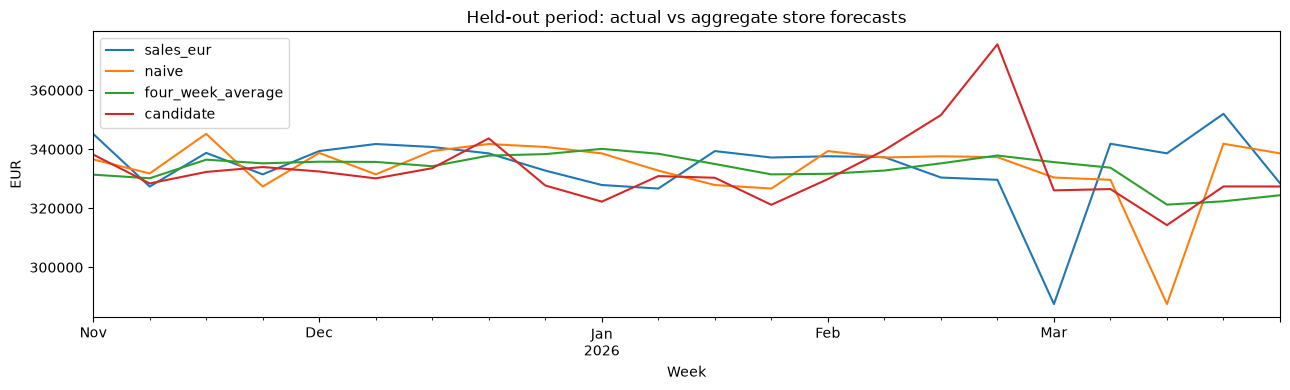

In [10]:
trainval = model_data[model_data.week_start + pd.Timedelta(days=7) <= test_origin].copy()
assert (trainval.week_start + pd.Timedelta(days=7) <= test_origin).all()
print('Final training labels:', len(trainval), trainval.week_start.min().date(), 'to', trainval.week_start.max().date())
final_model=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
final_model.fit(features(trainval),trainval.sales_eur)
eval_df=test[['store_id','week_start','sales_eur']].copy()
eval_df['naive']=test.lag_2.to_numpy()
eval_df['four_week_average']=test.trailing_4_mean.to_numpy()
eval_df['candidate']=final_model.predict(features(test))
comparison=pd.DataFrame({'Naive two weeks ago':metrics(eval_df.sales_eur,eval_df.naive),
                         'Four-week average':metrics(eval_df.sales_eur,eval_df.four_week_average),
                         'Candidate model':metrics(eval_df.sales_eur,eval_df.candidate)}).T
comparison['MAE_vs_naive_pct']=100*(comparison.MAE_EUR/comparison.loc['Naive two weeks ago','MAE_EUR']-1)
print('Final held-out test results:');display(comparison.round(2))
rows=[]
for store,grp in eval_df.groupby('store_id'):
    a=metrics(grp.sales_eur,grp.naive);b=metrics(grp.sales_eur,grp.candidate);c=metrics(grp.sales_eur,grp.four_week_average)
    rows.append({'store_id':store,'naive_MAE':a['MAE_EUR'],'candidate_MAE':b['MAE_EUR'],'four_week_MAE':c['MAE_EUR'],
                 'candidate_WAPE_pct':b['WAPE_pct'],'candidate_bias_EUR':b['Bias_EUR'],
                 'MAE_change_pct':100*(b['MAE_EUR']/a['MAE_EUR']-1),
                 'candidate_vs_four_week_pct':100*(b['MAE_EUR']/c['MAE_EUR']-1)})
store_results=pd.DataFrame(rows)
print('Store-level held-out results:');display(store_results.round(2))
fig,ax=plt.subplots(figsize=(13,4))
weekly=eval_df.groupby('week_start')[['sales_eur','naive','four_week_average','candidate']].sum()
weekly.plot(ax=ax);ax.set(title='Held-out period: actual vs aggregate store forecasts',ylabel='EUR',xlabel='Week');plt.tight_layout();plt.show()

In [11]:
naive_mae=comparison.loc['Naive two weeks ago','MAE_EUR']
rolling_mae=comparison.loc['Four-week average','MAE_EUR']
model_mae=comparison.loc['Candidate model','MAE_EUR']
improvement=100*(naive_mae-model_mae)/naive_mae
model_vs_rolling=100*(model_mae/rolling_mae-1)
store_worse=(store_results.MAE_change_pct>0).sum()
print(f'Test MAE improvement versus two-week naive: {improvement:.1f}%.')
print(f'Candidate MAE relative to four-week average: {model_vs_rolling:+.1f}% (positive means worse).')
print(f'Stores with worse candidate MAE than two-week naive: {store_worse} of {len(store_results)}.')
print('Original success criterion: at least 5% lower MAE than two-week naive and no store worse.')
print('Original criterion met:',improvement >= 5 and store_worse == 0)
if model_mae >= rolling_mae:
    print('Business decision: do not deploy the current candidate. The four-week average is stronger on this held-out period. Review data quality and return to preparation/validation.')
elif improvement >= 5 and store_worse == 0:
    print('Business decision: a controlled shadow pilot may be considered, with manager review.')
else:
    print('Business decision: do not deploy the current candidate. Review store-level errors and validation evidence first.')
print('Test-period comparisons are final evaluation and diagnostics, not a reason to tune the model on test data.')

print('Stores with worse candidate MAE than four-week average:', int((store_results.candidate_MAE > store_results.four_week_MAE).sum()), 'of',len(store_results))
print('Candidate overall bias (EUR):',round(comparison.loc['Candidate model','Bias_EUR'],2))

Test MAE improvement versus two-week naive: 14.9%.
Candidate MAE relative to four-week average: +7.1% (positive means worse).
Stores with worse candidate MAE than two-week naive: 4 of 9.
Original success criterion: at least 5% lower MAE than two-week naive and no store worse.
Original criterion met: False
Business decision: do not deploy the current candidate. The four-week average is stronger on this held-out period. Review data quality and return to preparation/validation.
Test-period comparisons are final evaluation and diagnostics, not a reason to tune the model on test data.
Stores with worse candidate MAE than four-week average: 6 of 9
Candidate overall bias (EUR): -137.71


In [12]:
worse_naive = store_results.loc[store_results.candidate_MAE > store_results.naive_MAE, 'store_id'].tolist()
worse_four = store_results.loc[store_results.candidate_MAE > store_results.four_week_MAE, 'store_id'].tolist()
validation_naive = metrics(val.sales_eur, val.lag_2)['MAE_EUR']
validation_four = metrics(val.sales_eur, val.trailing_4_mean)['MAE_EUR']
display(Markdown(f"""### Interpretation and remaining limits

The candidate's test MAE is **€{model_mae:,.2f}**, compared with **€{naive_mae:,.2f}** for the two-week baseline and **€{rolling_mae:,.2f}** for the four-week average. Improvement against the original baseline is **{improvement:.1f}%**; relative MAE against the four-week average is **{model_vs_rolling:+.1f}%**, where positive means worse. The original success criterion is **{'met' if improvement >= 5 and store_worse == 0 else 'not met'}**. We retain the original target of at least 5% improvement and no store deterioration.

Stores worse than the two-week baseline: **{', '.join(worse_naive) or 'none'}**. Stores worse than the four-week average: **{', '.join(worse_four) or 'none'}**. The preceding table reports each store's exact MAEs and relative differences. Test segments are diagnostic; they do not justify choosing store-specific models afterwards.

Validation MAEs are **€{validation_naive:,.2f}** for the two-week baseline, **€{validation_four:,.2f}** for the four-week average and **€{validation_results.iloc[0].MAE_EUR:,.2f}** for the best candidate setting. These values explain how much support the candidate had before final evaluation.

Overall candidate bias is **€{comparison.loc['Candidate model','Bias_EUR']:,.2f}** (prediction minus actual). Underforecasting may cause insufficient stock or staffing; overforecasting may cause unnecessary costs. These are potential consequences, not measured losses. Revenue does not identify exact quantities or staffing needs, and recorded revenue can understate demand when stock is unavailable.

**Decision:** do not deploy the current candidate automatically. Return to Data Preparation, verify suspicious records and confirm planning deadlines and data publication delays. The printed evaluation decision above reports the performance conditions. A revised model requires later validation and a fresh prospective evaluation before operational use.

The original test has already been examined and this revision corrects forecast timing. These are retrospective corrected results, not a fresh untouched test. We do not tune features or thresholds using these results. Promotion schedules may be assessed in a future cycle only if their Thursday availability is confirmed.
"""))

# Diagnose the observed low week and its later use in the naive forecast.
s09 = eval_df.loc[eval_df.store_id == 'S09'].copy()
s09['naive_absolute_error'] = (s09.naive - s09.sales_eur).abs()
diagnostic = s09.loc[s09.week_start.isin(pd.to_datetime(['2026-03-02', '2026-03-16']))]
print('S09 diagnostic only: low recorded week and its lag_2 effect two weeks later')
display(diagnostic[['week_start','sales_eur','naive','four_week_average','candidate','naive_absolute_error']].round(2))
display(Markdown('The low recorded week affects the baseline both as an outcome and, two weeks later, as historical input. This helps explain sensitivity of the measured comparison; it does not make the measured improvement unreal or prove that the record is wrong. No test records are removed.'))


### Interpretation and remaining limits

The candidate's test MAE is **€2,339.66**, compared with **€2,749.18** for the two-week baseline and **€2,183.66** for the four-week average. Improvement against the original baseline is **14.9%**; relative MAE against the four-week average is **+7.1%**, where positive means worse. The original success criterion is **not met**. We retain the original target of at least 5% improvement and no store deterioration.

Stores worse than the two-week baseline: **S01, S03, S05, S06**. Stores worse than the four-week average: **S01, S02, S03, S04, S05, S06**. The preceding table reports each store's exact MAEs and relative differences. Test segments are diagnostic; they do not justify choosing store-specific models afterwards.

Validation MAEs are **€2,151.15** for the two-week baseline, **€1,716.92** for the four-week average and **€2,562.04** for the best candidate setting. These values explain how much support the candidate had before final evaluation.

Overall candidate bias is **€-137.71** (prediction minus actual). Underforecasting may cause insufficient stock or staffing; overforecasting may cause unnecessary costs. These are potential consequences, not measured losses. Revenue does not identify exact quantities or staffing needs, and recorded revenue can understate demand when stock is unavailable.

**Decision:** do not deploy the current candidate automatically. Return to Data Preparation, verify suspicious records and confirm planning deadlines and data publication delays. The printed evaluation decision above reports the performance conditions. A revised model requires later validation and a fresh prospective evaluation before operational use.

The original test has already been examined and this revision corrects forecast timing. These are retrospective corrected results, not a fresh untouched test. We do not tune features or thresholds using these results. Promotion schedules may be assessed in a future cycle only if their Thursday availability is confirmed.


S09 diagnostic only: low recorded week and its lag_2 effect two weeks later


/tmp/ipykernel_16311/3824276585.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(diagnostic[['week_start','sales_eur','naive','four_week_average','candidate','naive_absolute_error']].round(2))


,week_start,sales_eur,naive,four_week_average,candidate,naive_absolute_error
1057,2026-03-02,3791.04,44065.48,45276.46,43234.68,40274.44
1059,2026-03-16,48324.38,3791.04,34448.37,37145.64,44533.34


The low recorded week affects the baseline both as an outcome and, two weeks later, as historical input. This helps explain sensitivity of the measured comparison; it does not make the measured improvement unreal or prove that the record is wrong. No test records are removed.

### Facts, assumptions and our choices

- **Dataset facts:** Nine stores, weekly `sales_eur`, missing fields, duplicate store-week records, and the observed validation and test metrics come from the supplied data and code.
- **Business assumptions:** Thursday is early enough for planning; managers can use revenue forecasts to support decisions; the company can check questionable records. These points need confirmation.
- **Our analytical choices:** Forecast revenue rather than units, use `lag_2` and the four-week mean as baselines, average duplicate `sales_eur`, exclude unavailable features, use chronological splits, and keep the original 5% goal. The original analytical choices are retained; this revision corrects training-label availability after the original test was already inspected. It is a retrospective audit, not a fresh untouched evaluation.

The final test is used to **evaluate and make a business recommendation**, not to choose new features, thresholds or model settings. Any future model revision needs a new time-based validation and a fresh final evaluation.

### Why can a simple average beat the candidate?

The validation-only sensitivity experiment is direct evidence about the effect of excluding flagged training rows, while its bias comparison and remaining lag contamination limit the conclusion. The exact changes are reported above. The store table and validation comparisons show where each method performs better; they do not establish the underlying business cause.

Plausible explanations include a stable recent revenue level that a short average captures effectively, limited historical coverage for learning calendar interactions, and sensitivity of boosted trees to unusual observations. These are hypotheses, not proven autocorrelation or overfitting findings: we have not reported an autocorrelation analysis, learning curves or repeated time-based validation that would establish them.

The candidate is **not** an untuned default model. We compare 4, 8 and 16 leaf nodes on validation and use 150 iterations, learning rate 0.05 and L2 regularization 10. This is a deliberately limited search, not exhaustive optimization. A future cycle could assess a few predeclared alternatives using rolling-origin validation, with training-label availability checked at every origin. Model sophistication is not itself a goal, and the current test must not become the tuning set.

The four-week average is a transparent benchmark and a possible manager-reviewed planning reference, subject to confirming deadlines, data availability and consequences. Lower historical MAE alone does not justify immediate automatic production use or a claim of zero operating cost. Additional signals may be assessed only when known at forecast time: published promotion plans or weather forecasts, for example, rather than realised target-week weather or footfall. Any proposed store-specific method must be evaluated on future validation data rather than selected from the current store test results.


## Phase 6 — Deployment / Next Iteration

**Current decision:** do not automatically use the machine learning model for stock or staffing decisions. We first investigate the unusual sales values with the data owner and validate a revised model. This is a design for a possible future version, not a claim that the current model is ready.

We would produce a forecast on **Thursday** for the next week, using only completed sales weeks. The retailer must confirm that this is early enough. Managers can review the forecast, compare it with the four-week average and record any override and its reason. Revenue supports general planning, but cannot directly determine exact product quantities or staffing levels.

Before every forecast, we would check for missing data, duplicated store-weeks and unusually high or low sales. We would save forecasts before the target week and compare them with actual revenue afterwards. We would monitor MAE and bias for each store and overall. **Bias is prediction minus actual.** For a future model, we would review both signed bias and absolute bias against the four-week average over the same weeks. A less negative bias can still be excessive overforecasting. These are proposed checks, not proven business cost thresholds. MAE must also be checked because bias alone can hide large errors.

We would use a **shadow pilot** for an improved model: record its forecasts without letting them automatically change real orders or staffing. An initial eight-week review gives more observations than four weeks, but is still limited. If the candidate performs worse than the four-week average over the eight-week review, or if important data is unreliable, we use the simple baseline and investigate. We would **review the model and data every month**. A retraining investigation is triggered if the candidate has higher MAE than the four-week average across the proposed eight-week monitoring window, if any store has worse MAE than the baseline across two consecutive eight-week reviews, or if the data owner confirms a major change in sales patterns or definitions. These are proposed review triggers, not measured company cost limits. A trigger does not mean automatic retraining or automatic deployment. We would retrain only after checking data quality and validate the updated model on later weeks before considering another shadow pilot. Monthly review is our proposed schedule, not a confirmed company rule. Managers always keep the final decision.

**Proposed responsibilities and availability:** the retailer would appoint a data owner to check definitions, duplicate records and unusual revenue, and an analyst to produce forecasts and monitor errors. Store managers would approve planning actions and record overrides; these roles require company agreement. We assume final revenue for a completed week is available before the following Thursday. If this is false, increase the data delay, rebuild the features and revalidate.

Monthly monitoring would use the latest eight completed weeks. Consecutive monthly reviews therefore overlap and are not independent evidence. A store-level trigger requires deterioration in two successive monthly reviews of these rolling eight-week windows. During the initial pilot, the first eight-week window must finish before its review. If historical revenue is missing, neither the model nor its baseline should silently use incomplete history: pause the affected automatic forecast, alert the data owner and let the manager use documented manual planning until the data is repaired.


## Individual Understanding

Tijn

In previous assignments, I sometimes made conclusions too quickly without checking the data carefully enough. In this assignment, I learned to explain the difference between what the data shows and what we assume. For example, we chose Thursday as the planning day, but we do not know if this is the company's actual deadline. This choice means that we can only use sales information that is complete and available on that Thursday, both for the input features and for training the model.

I also learned that a better overall result does not mean the model works better for every store. Our model can beat one baseline but still perform worse than another simple method. Next time, I would check the timing of the available data earlier and look at both the overall results and the results for each store before making a recommendation.

Jayden

In previous assignments, I learned that we need to be careful when explaining patterns in the data. This assignment showed me that the same applies to missing and unusual values. A missing promotion label does not mean there was no promotion, and a very high sales value is not automatically wrong. We should investigate these values before changing them.

I also learned to look at more than one result when comparing models. In the sensitivity check, we looked at what happened when we left unusual rows out of training. A lower MAE means smaller errors on average, but we also need to check whether predictions are usually too high or too low. Those unusual sales values can also still appear in later lag features. Next time, I would explain these limits more clearly and compare the model with simple baselines before deciding whether the business should use it.

**Daniel:**

In our previous assignment, we replaced one extreme sales value without checking whether it was really wrong, and we calculated the limit for unusual values on the full dataset before splitting the data. I learned that you have to investigate a strange value before you change it, and that every rule you learn from the data should come from the training period only. In this assignment, I compared the extreme weeks with footfall. Those weeks had a normal number of visitors but about four times the normal revenue per visitor, which suggests a recording error, although it does not prove one. The validation-only sensitivity comparison shows how excluding flagged training rows changes MAE and bias; the table above gives the current results after the timing correction. The values can still appear in later lag inputs, so this is not a complete cleaning experiment. I also learned to compare a model with more than one simple baseline. I learned that beating one baseline is not sufficient: we must compare both baselines and the original success criterion before recommending deployment.